# Activity 1: Multiple Linear Regression Worksheet
**Unit I – Regression Foundations & Linear Regression**

## 1. Objective & Problem Statement
**Objective:** To understand how multiple input variables together explain a continuous target, fit a Multiple Linear Regression model manually (on a small sample) and programmatically, compare it against a single-feature baseline, interpret coefficients and intercept, check regression assumptions (including multicollinearity), and evaluate performance on unseen test data.

**Problem Statement:** Given advertising expenditure across three media channels (`TV`, `Radio`, and `Newspaper`, in thousands of USD), predict product `Sales` (in thousands of units) using Multiple Linear Regression, verify manual normal-equation calculations against a library implementation, and assess whether adding `Radio` and `Newspaper` improves predictive accuracy over `TV` alone.


## 2. Environment Setup & Dataset Loading
**Dataset:** Advertising Dataset (200 market observations)  
**Original Source:** *An Introduction to Statistical Learning* (James, Witten, Hastie, Tibshirani) — [Advertising.csv](https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv)

In [9]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

print(f"Python: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")

local_path = "Advertising.csv"
url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
try:
    df_raw = pd.read_csv(local_path)
except FileNotFoundError:
    df_raw = pd.read_csv(url)

print("Raw dataset shape:", df_raw.shape)
df_raw.head()
print(df_raw.head().to_string())

Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3
Raw dataset shape: (200, 5)
   Unnamed: 0     TV  Radio  Newspaper  Sales
0           1  230.1   37.8       69.2   22.1
1           2   44.5   39.3       45.1   10.4
2           3   17.2   45.9       69.3    9.3
3           4  151.5   41.3       58.5   18.5
4           5  180.8   10.8       58.4   12.9


## 3. Data Inspection, Types, Descriptive Statistics & Cleaning
We inspect data types, summary statistics, missing values, and duplicate records. Notice `Unnamed: 0` is a 1-based record identifier and must be dropped so it is never used as an input feature.

In [10]:
print("Data Types:\n", df_raw.dtypes)
print("\nMissing Values:\n", df_raw.isnull().sum())
print("\nDuplicate Rows:", df_raw.duplicated().sum())

# Drop record ID column
df = df_raw.drop(columns=["Unnamed: 0"]).copy()
print("\nCleaned dataset shape:", df.shape)
print("\nDescriptive Statistics (TV, Radio, Newspaper in $k; Sales in k units):")
desc = df.describe().T
desc["range"] = desc["max"] - desc["min"]
print(desc[["count", "mean", "std", "min", "50%", "max", "range"]].round(4).to_string())

Data Types:
 Unnamed: 0      int64
TV            float64
Radio         float64
Newspaper     float64
Sales         float64
dtype: object

Missing Values:
 Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

Duplicate Rows: 0

Cleaned dataset shape: (200, 4)

Descriptive Statistics (TV, Radio, Newspaper in $k; Sales in k units):
           count      mean      std  min     50%    max  range
TV         200.0  147.0425  85.8542  0.7  149.75  296.4  295.7
Radio      200.0   23.2640  14.8468  0.0   22.90   49.6   49.6
Newspaper  200.0   30.5540  21.7786  0.3   25.75  114.0  113.7
Sales      200.0   14.0225   5.2175  1.6   12.90   27.0   25.4


## 4. Exploratory Visualisation & Correlation Analysis


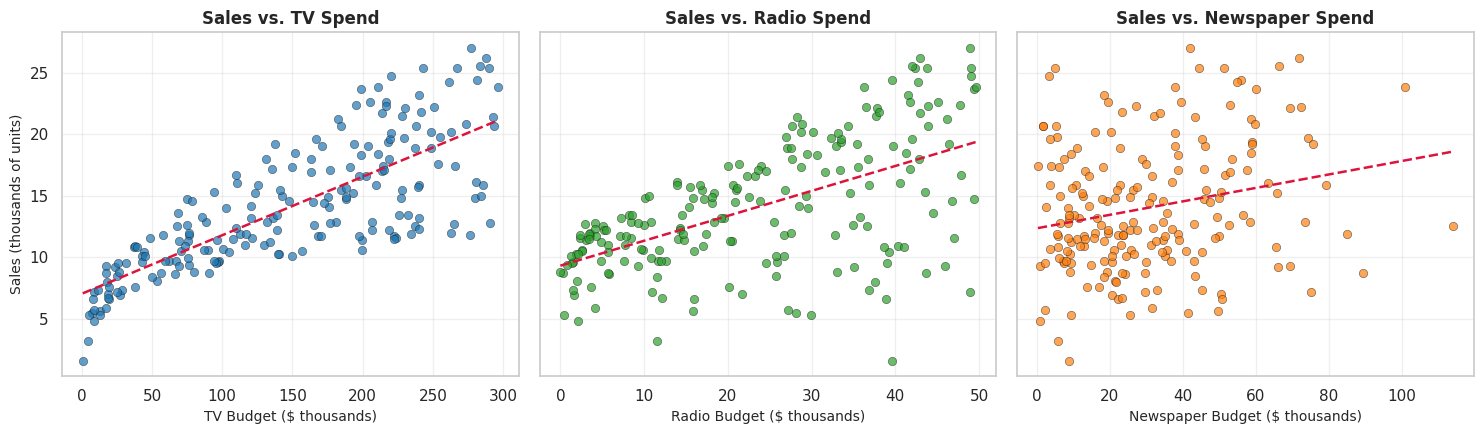

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
features = ["TV", "Radio", "Newspaper"]
colors = ["#1f77b4", "#2ca02c", "#ff7f0e"]

for ax, feat, col in zip(axes, features, colors):
    ax.scatter(df[feat], df["Sales"], alpha=0.7, color=col, edgecolors="k", linewidth=0.4)
    m, b = np.polyfit(df[feat], df["Sales"], 1)
    x_line = np.linspace(df[feat].min(), df[feat].max(), 100)
    ax.plot(x_line, m * x_line + b, color="crimson", linewidth=1.8, linestyle="--")
    ax.set_title(f"Sales vs. {feat} Spend", fontsize=12, fontweight="bold")
    ax.set_xlabel(f"{feat} Budget ($ thousands)", fontsize=10)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel("Sales (thousands of units)", fontsize=10)
plt.tight_layout()
plt.show()

Correlation Matrix:
                TV   Radio  Newspaper   Sales
TV         1.0000  0.0548     0.0566  0.7822
Radio      0.0548  1.0000     0.3541  0.5762
Newspaper  0.0566  0.3541     1.0000  0.2283
Sales      0.7822  0.5762     0.2283  1.0000


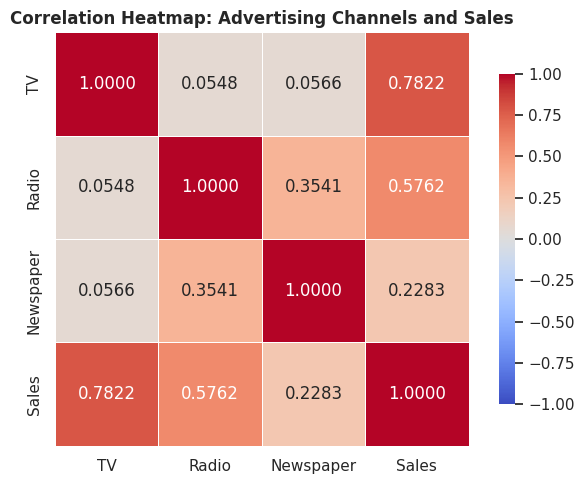

In [12]:
corr_matrix = df.corr()
print("Correlation Matrix:\n", corr_matrix.round(4).to_string())

plt.figure(figsize=(6.5, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".4f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap: Advertising Channels and Sales", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Manual Calculation Worksheet (6 Observations, 2 Features: TV & Radio)


In [13]:
sample = df.iloc[:6][["TV", "Radio", "Sales"]].copy()
print("Selected 6-Observation Sample:\n", sample.to_string())

X_man = np.column_stack([np.ones(len(sample)), sample["TV"].values, sample["Radio"].values])
y_man = sample["Sales"].values

print("\nDesign Matrix X (6x3):")
print(X_man)
print("\nTarget Vector y (6x1):")
print(y_man)

XtX = X_man.T @ X_man
Xty = X_man.T @ y_man
print("\nX^T X:")
print(np.round(XtX, 4))
print("\nX^T y:")
print(np.round(Xty, 4))

XtX_inv = np.linalg.inv(XtX)
b_man = XtX_inv @ Xty
print("\n(X^T X)^(-1):")
print(np.round(XtX_inv, 8))
print(f"\nSolved Manual Coefficients: b0 = {b_man[0]:.6f}, b1 (TV) = {b_man[1]:.6f}, b2 (Radio) = {b_man[2]:.6f}")

# Predict for observation 1 (index 0) and compute residual
y_hat_obs1 = b_man[0] + b_man[1] * X_man[0, 1] + b_man[2] * X_man[0, 2]
res_obs1 = y_man[0] - y_hat_obs1
print(f"\nObservation 1 Actual Sales = {y_man[0]:.4f}")
print(f"Observation 1 Predicted Sales = {y_hat_obs1:.6f}")
print(f"Observation 1 Residual (y - y_hat) = {res_obs1:.6f}")

# Verify with numpy.linalg.lstsq
b_lib_sample, _, _, _ = np.linalg.lstsq(X_man, y_man, rcond=None)
print(f"\nLibrary lstsq Verification: b0 = {b_lib_sample[0]:.6f}, b1 = {b_lib_sample[1]:.6f}, b2 = {b_lib_sample[2]:.6f}")
print(f"Max absolute difference: {np.max(np.abs(b_man - b_lib_sample)):.2e}")

Selected 6-Observation Sample:
       TV  Radio  Sales
0  230.1   37.8   22.1
1   44.5   39.3   10.4
2   17.2   45.9    9.3
3  151.5   41.3   18.5
4  180.8   10.8   12.9
5    8.7   48.9    7.2

Design Matrix X (6x3):
[[  1.  230.1  37.8]
 [  1.   44.5  39.3]
 [  1.   17.2  45.9]
 [  1.  151.5  41.3]
 [  1.  180.8  10.8]
 [  1.    8.7  48.9]]

Target Vector y (6x1):
[22.1 10.4  9.3 18.5 12.9  7.2]

X^T X:
[[6.0000000e+00 6.3280000e+02 2.2400000e+02]
 [6.3280000e+02 1.1093868e+05 1.9871130e+04]
 [2.2400000e+02 1.9871130e+04 9.2936800e+03]]

X^T y:
[   80.4  10905.68  2926.42]

(X^T X)^(-1):
[[ 3.91793415e+00 -8.80631000e-03 -7.56025500e-02]
 [-8.80631000e-03  3.44000000e-05  1.38700000e-04]
 [-7.56025500e-02  1.38700000e-04  1.63325000e-03]]

Solved Manual Coefficients: b0 = -2.281725, b1 (TV) = 0.073039, b2 (Radio) = 0.213710

Observation 1 Actual Sales = 22.1000
Observation 1 Predicted Sales = 22.602884
Observation 1 Residual (y - y_hat) = -0.502884

Library lstsq Verification: b0 = -2

## 6. Train-Test Split (80:20) & Baseline vs. Multiple Linear Regression
We split the 200 observations into 160 training records (80%) and 40 test records (20%) with `random_state=42`. We fit:


In [14]:
indices = np.arange(len(df))
rng = np.random.default_rng(RANDOM_STATE)
shuffled_idx = rng.permutation(indices)
split_point = int(0.8 * len(df))
train_idx, test_idx = shuffled_idx[:split_point], shuffled_idx[split_point:]

train_df = df.iloc[train_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)
print(f"Train observations: {len(train_df)} | Test observations: {len(test_df)}")

def fit_ols(X, y):
    X_design = np.column_stack([np.ones(len(X)), X])
    beta, _, _, _ = np.linalg.lstsq(X_design, y, rcond=None)
    return beta[0], beta[1:]

def predict_ols(X, intercept, coefs):
    return intercept + X @ coefs

def regression_metrics(y_true, y_pred, p):
    n = len(y_true)
    residuals = y_true - y_pred
    mae = np.mean(np.abs(residuals))
    mse = np.mean(residuals ** 2)
    rmse = np.sqrt(mse)
    ss_res = np.sum(residuals ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - ss_res / ss_tot
    adj_r2 = 1.0 - (1.0 - r2) * (n - 1) / (n - p - 1)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adj_R2": adj_r2}

# 1. Single-feature baseline (TV)
X_train_1 = train_df[["TV"]].values
X_test_1 = test_df[["TV"]].values
y_train = train_df["Sales"].values
y_test = test_df["Sales"].values

b0_single, b_single = fit_ols(X_train_1, y_train)
y_pred_test_1 = predict_ols(X_test_1, b0_single, b_single)
metrics_1 = regression_metrics(y_test, y_pred_test_1, p=1)
print(f"\nSingle-Feature Model: Sales = {b0_single:.4f} + {b_single[0]:.6f} * TV")
print("Single-Feature Test Metrics:", {k: round(v, 4) for k, v in metrics_1.items()})

# 2. Multiple Linear Regression (TV, Radio, Newspaper)
X_train_m = train_df[features].values
X_test_m = test_df[features].values

b0_mult, b_mult = fit_ols(X_train_m, y_train)
y_pred_test_m = predict_ols(X_test_m, b0_mult, b_mult)
metrics_m = regression_metrics(y_test, y_pred_test_m, p=3)
print(f"\nMultiple Linear Regression: Sales = {b0_mult:.4f} + {b_mult[0]:.6f}*TV + {b_mult[1]:.6f}*Radio + {b_mult[2]:.6f}*Newspaper")
print("Multiple Model Test Metrics:", {k: round(v, 4) for k, v in metrics_m.items()})

# 3. Standardized coefficients (fit scaler on training data only)
train_mean = X_train_m.mean(axis=0)
train_std = X_train_m.std(axis=0, ddof=0)
X_train_scaled = (X_train_m - train_mean) / train_std
b0_std, b_std = fit_ols(X_train_scaled, y_train)
print("\nStandardized Coefficients (relative influence, training data only):")
for fname, c_raw, c_std in zip(features, b_mult, b_std):
    print(f"  {fname:10s}: Raw = {c_raw:+.6f} | Standardized = {c_std:+.4f}")

# Comparison table
comp_df = pd.DataFrame([
    {"Model": "Single-Feature (TV)", **metrics_1},
    {"Model": "Multiple (TV, Radio, Newspaper)", **metrics_m},
])
print("\nModel Comparison Table (Test Set):")
print(comp_df.round(4).to_string(index=False))

Train observations: 160 | Test observations: 40

Single-Feature Model: Sales = 6.9177 + 0.046973 * TV
Single-Feature Test Metrics: {'MAE': np.float64(2.92), 'MSE': np.float64(13.5526), 'RMSE': np.float64(3.6814), 'R2': np.float64(0.4947), 'Adj_R2': np.float64(0.4814)}

Multiple Linear Regression: Sales = 3.0389 + 0.046363*TV + 0.175484*Radio + 0.001084*Newspaper
Multiple Model Test Metrics: {'MAE': np.float64(1.2575), 'MSE': np.float64(2.5304), 'RMSE': np.float64(1.5907), 'R2': np.float64(0.9056), 'Adj_R2': np.float64(0.8978)}

Standardized Coefficients (relative influence, training data only):
  TV        : Raw = +0.046363 | Standardized = +3.9377
  Radio     : Raw = +0.175484 | Standardized = +2.6197
  Newspaper : Raw = +0.001084 | Standardized = +0.0231

Model Comparison Table (Test Set):
                          Model    MAE     MSE   RMSE     R2  Adj_R2
            Single-Feature (TV) 2.9200 13.5526 3.6814 0.4947  0.4814
Multiple (TV, Radio, Newspaper) 1.2575  2.5304 1.5907 0.905

## 7. Actual vs. Predicted Comparison & Residual Diagnostics


Sample Test Set Predictions (First 10 Test Records):
   TV  Radio  Newspaper  Actual_Sales  Predicted_Sales  Residual
136.2   19.2       16.6          13.2          12.7407    0.4593
188.4   18.1       25.6          14.9          14.9776   -0.0776
228.3   16.9       26.2          15.5          16.6175   -1.1175
284.3   10.6        6.4          15.0          18.0868   -3.0868
195.4   47.7       52.9          22.4          20.5261    1.8739
 53.5    2.0       21.4           8.1           5.8934    2.2066
255.4   26.9        5.5          19.8          19.6064    0.1936
273.7   28.9       59.7          20.8          20.8645   -0.0645
112.9   17.4       38.6          11.9          11.3685    0.5315
 67.8   36.6      114.0          12.5          12.7285   -0.2285


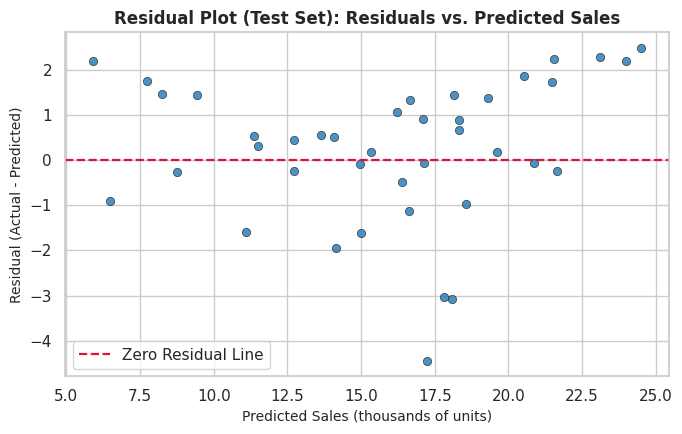

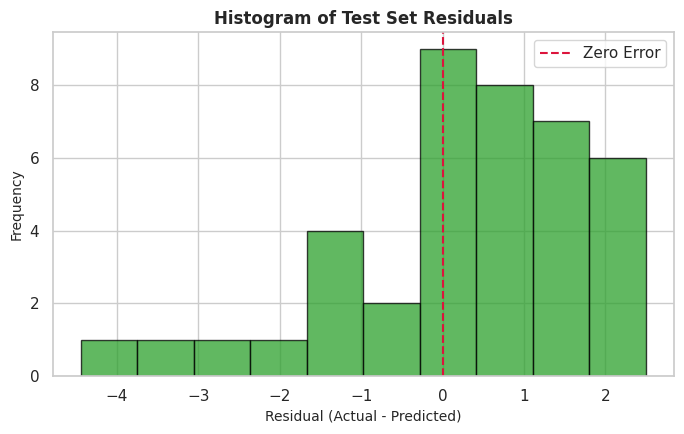

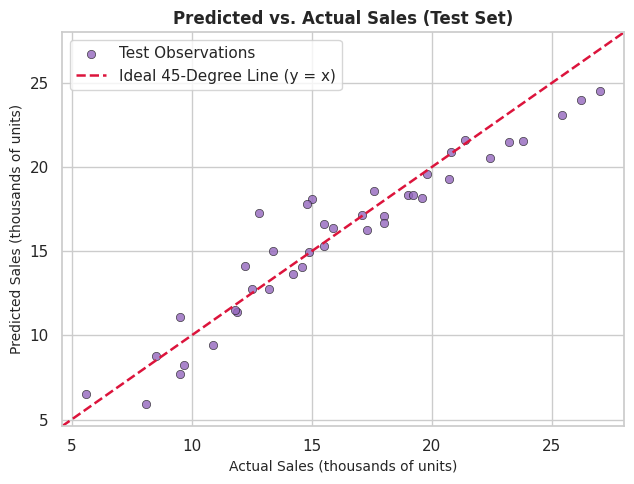

In [15]:
pred_sample = pd.DataFrame({
    "TV": test_df["TV"].values[:10],
    "Radio": test_df["Radio"].values[:10],
    "Newspaper": test_df["Newspaper"].values[:10],
    "Actual_Sales": y_test[:10],
    "Predicted_Sales": np.round(y_pred_test_m[:10], 4),
    "Residual": np.round(y_test[:10] - y_pred_test_m[:10], 4),
})
print("Sample Test Set Predictions (First 10 Test Records):")
print(pred_sample.to_string(index=False))

residuals_test = y_test - y_pred_test_m

# Plot 1: Residual Plot
plt.figure(figsize=(7, 4.5))
plt.scatter(y_pred_test_m, residuals_test, color="#1f77b4", alpha=0.8, edgecolors="k", linewidth=0.5)
plt.axhline(0, color="crimson", linestyle="--", linewidth=1.6, label="Zero Residual Line")
plt.title("Residual Plot (Test Set): Residuals vs. Predicted Sales", fontsize=12, fontweight="bold")
plt.xlabel("Predicted Sales (thousands of units)", fontsize=10)
plt.ylabel("Residual (Actual - Predicted)", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 2: Residual Histogram
plt.figure(figsize=(7, 4.5))
plt.hist(residuals_test, bins=10, color="#2ca02c", alpha=0.75, edgecolor="black")
plt.axvline(0, color="crimson", linestyle="--", linewidth=1.5, label="Zero Error")
plt.title("Histogram of Test Set Residuals", fontsize=12, fontweight="bold")
plt.xlabel("Residual (Actual - Predicted)", fontsize=10)
plt.ylabel("Frequency", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

# Plot 3: Predicted vs. Actual with 45-degree line
plt.figure(figsize=(6.5, 5))
plt.scatter(y_test, y_pred_test_m, color="#9467bd", alpha=0.8, edgecolors="k", linewidth=0.5, label="Test Observations")
lims = [min(y_test.min(), y_pred_test_m.min()) - 1, max(y_test.max(), y_pred_test_m.max()) + 1]
plt.plot(lims, lims, color="crimson", linestyle="--", linewidth=1.8, label="Ideal 45-Degree Line (y = x)")
plt.xlim(lims)
plt.ylim(lims)
plt.title("Predicted vs. Actual Sales (Test Set)", fontsize=12, fontweight="bold")
plt.xlabel("Actual Sales (thousands of units)", fontsize=10)
plt.ylabel("Predicted Sales (thousands of units)", fontsize=10)
plt.legend()
plt.tight_layout()
plt.show()

## 8. Variance Inflation Factor (VIF) & Prediction for a New Example


In [16]:
vif_rows = []
for i, fname in enumerate(features):
    y_i = X_train_m[:, i]
    X_other = np.delete(X_train_m, i, axis=1)
    b0_i, b_i = fit_ols(X_other, y_i)
    y_i_pred = predict_ols(X_other, b0_i, b_i)
    ss_res_i = np.sum((y_i - y_i_pred) ** 2)
    ss_tot_i = np.sum((y_i - np.mean(y_i)) ** 2)
    r2_i = 1.0 - ss_res_i / ss_tot_i
    vif_i = 1.0 / (1.0 - r2_i)
    vif_rows.append({"Feature": fname, "R2_with_others": round(r2_i, 4), "VIF": round(vif_i, 4)})

vif_df = pd.DataFrame(vif_rows)
print("Variance Inflation Factor (VIF) on Training Set:")
print(vif_df.to_string(index=False))

new_campaign = np.array([[150.0, 25.0, 20.0]])
new_pred = predict_ols(new_campaign, b0_mult, b_mult)[0]
print(f"\nNew Campaign Budget: TV=$150.0k, Radio=$25.0k, Newspaper=$20.0k")
print(f"Predicted Sales: {new_pred:.4f} thousand units ({new_pred*1000:.0f} units)")

Variance Inflation Factor (VIF) on Training Set:
  Feature  R2_with_others    VIF
       TV          0.0079 1.0079
    Radio          0.1652 1.1979
Newspaper          0.1712 1.2066

New Campaign Budget: TV=$150.0k, Radio=$25.0k, Newspaper=$20.0k
Predicted Sales: 14.4020 thousand units (14402 units)
